# Aviation Accidents Analysis

You are part of a consulting firm that is tasked to do an analysis of commercial and passenger jet airline safety. The client (an airline/airplane insurer) is interested in knowing what types of aircraft (makes/models) exhibit low rates of total destruction and low likelihood of fatal or serious passenger injuries in the event of an accident. They are also interested in any general variables/conditions that might be at play. Your analysis will be based off of aviation accident data accumulated from the years 1948-2023. 

Our client is only interested in airplane makes/models that are professional builds and could potentially still be active. Assume a max lifetime of 40 years for a make/model retirement and make sure to filter your data accordingly (i.e. from 1983 onwards). They would also like separate recommendations for small aircraft vs. larger passenger models. **In addition, make sure that claims that you make are statistically robust and that you have enough samples when making comparisons between groups.**


In this summative assessment you will demonstrate your ability to:
- **Use Pandas to load, inspect, and clean the dataset appropriately.**
- **Transform relevant columns to create measures that address the problem at hand.**
- conduct EDA: visualization and statistical measures to systematically understand the structure of the data
- recommend a set of airplanes and makes conforming to the client's request and identify at least *two* factors contributing to airplane safety. You must provide supporting evidence (visuals, summary statistics, tables) for each claim you make.

### Make relevant library imports

In [226]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

## Data Loading and Inspection

### Load in data from the relevant directory and inspect the dataframe.
- inspect NaNs, datatypes, and summary statistics

In [227]:
aviation_data = pd.read_csv('C:/Users/user/OneDrive/Desktop/Data analysis Jet Airline Safety/dsc-course0-m8-lab/data/AviationData.csv', encoding='latin-1')

C:\Users\user\AppData\Local\Temp\ipykernel_49952\2784264797.py:1: DtypeWarning: Columns (6: Latitude, 7: Longitude, 28: Broad.phase.of.flight) have mixed types. Specify dtype option on import or set low_memory=False.
  aviation_data = pd.read_csv('C:/Users/user/OneDrive/Desktop/Data analysis Jet Airline Safety/dsc-course0-m8-lab/data/AviationData.csv', encoding='latin-1')


In [228]:
aviation_data_copy = aviation_data.copy()
aviation_data_copy.describe()

,Number.of.Engines,Total.Fatal.Injuries,Total.Serious.Injuries,Total.Minor.Injuries,Total.Uninjured
count,82805.000000,77488.000000,76379.000000,76956.000000,82977.000000
mean,1.146585,0.647855,0.279881,0.357061,5.325440
std,0.446510,5.485960,1.544084,2.235625,27.913634
min,0.000000,0.000000,0.000000,0.000000,0.000000
25%,1.000000,0.000000,0.000000,0.000000,0.000000
50%,1.000000,0.000000,0.000000,0.000000,1.000000
75%,1.000000,0.000000,0.000000,0.000000,2.000000
max,8.000000,349.000000,161.000000,380.000000,699.000000


In [229]:
aviation_data_copy.info()

<class 'pandas.DataFrame'>
RangeIndex: 88889 entries, 0 to 88888
Data columns (total 31 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   Event.Id                88889 non-null  str    
 1   Investigation.Type      88889 non-null  str    
 2   Accident.Number         88889 non-null  str    
 3   Event.Date              88889 non-null  str    
 4   Location                88837 non-null  str    
 5   Country                 88663 non-null  str    
 6   Latitude                34382 non-null  object 
 7   Longitude               34373 non-null  object 
 8   Airport.Code            50132 non-null  str    
 9   Airport.Name            52704 non-null  str    
 10  Injury.Severity         87889 non-null  str    
 11  Aircraft.damage         85695 non-null  str    
 12  Aircraft.Category       32287 non-null  str    
 13  Registration.Number     87507 non-null  str    
 14  Make                    88826 non-null  str    
 

## Data Cleaning

### Filtering aircrafts and events

We want to filter the dataset to include aircraft that the client is interested in an analysis of:
- inspect relevant columns
- figure out any reasonable imputations
- filter the dataset

In [230]:
aviation_data_copy['Event.Date'] = pd.to_datetime(aviation_data_copy['Event.Date'])
aviation_data_copy['Publication.Date'] = pd.to_datetime(aviation_data_copy['Publication.Date'])
aviation_data_copy.info()

C:\Users\user\AppData\Local\Temp\ipykernel_49952\2150333144.py:2: UserWarning: Parsing dates in %d-%m-%Y format when dayfirst=False (the default) was specified. Pass `dayfirst=True` or specify a format to silence this warning.
  aviation_data_copy['Publication.Date'] = pd.to_datetime(aviation_data_copy['Publication.Date'])


<class 'pandas.DataFrame'>
RangeIndex: 88889 entries, 0 to 88888
Data columns (total 31 columns):
 #   Column                  Non-Null Count  Dtype         
---  ------                  --------------  -----         
 0   Event.Id                88889 non-null  str           
 1   Investigation.Type      88889 non-null  str           
 2   Accident.Number         88889 non-null  str           
 3   Event.Date              88889 non-null  datetime64[us]
 4   Location                88837 non-null  str           
 5   Country                 88663 non-null  str           
 6   Latitude                34382 non-null  object        
 7   Longitude               34373 non-null  object        
 8   Airport.Code            50132 non-null  str           
 9   Airport.Name            52704 non-null  str           
 10  Injury.Severity         87889 non-null  str           
 11  Aircraft.damage         85695 non-null  str           
 12  Aircraft.Category       32287 non-null  str           
 1

In [231]:
#For any duplicates
aviation_data_copy.duplicated().sum()

np.int64(0)

In [232]:
# I thought of spliting the location to city and state which makes things easier for data analysis
area = aviation_data_copy['Location'].str.split(', ', expand=True)
aviation_data_copy['City'] = area[0]
aviation_data_copy['State'] = area[1]
aviation_data_copy.head()

,Event.Id,Investigation.Type,Accident.Number,Event.Date,Location,Country,Latitude,Longitude,Airport.Code,Airport.Name,...,Total.Fatal.Injuries,Total.Serious.Injuries,Total.Minor.Injuries,Total.Uninjured,Weather.Condition,Broad.phase.of.flight,Report.Status,Publication.Date,City,State
0,20001218X45444,Accident,SEA87LA080,1948-10-24,"MOOSE CREEK, ID",United States,NaN,NaN,NaN,NaN,...,2.0,0.0,0.0,0.0,UNK,Cruise,Probable Cause,NaT,MOOSE CREEK,ID
1,20001218X45447,Accident,LAX94LA336,1962-07-19,"BRIDGEPORT, CA",United States,NaN,NaN,NaN,NaN,...,4.0,0.0,0.0,0.0,UNK,Unknown,Probable Cause,1996-09-19,BRIDGEPORT,CA
2,20061025X01555,Accident,NYC07LA005,1974-08-30,"Saltville, VA",United States,36.922223,-81.878056,NaN,NaN,...,3.0,NaN,NaN,NaN,IMC,Cruise,Probable Cause,2007-02-26,Saltville,VA
3,20001218X45448,Accident,LAX96LA321,1977-06-19,"EUREKA, CA",United States,NaN,NaN,NaN,NaN,...,2.0,0.0,0.0,0.0,IMC,Cruise,Probable Cause,2000-09-12,EUREKA,CA
4,20041105X01764,Accident,CHI79FA064,1979-08-02,"Canton, OH",United States,NaN,NaN,NaN,NaN,...,1.0,2.0,NaN,0.0,VMC,Approach,Probable Cause,1980-04-16,Canton,OH


In [233]:
#Standardizing the datetime and categorical values by making the datapoints uniform

aviation_data_copy['City'] = aviation_data_copy['City'].str.capitalize()
aviation_data_copy['State'] = aviation_data_copy['State'].str.upper()
aviation_data_copy['Country'] = aviation_data_copy['Country'].str.upper()
aviation_data_copy['Aircraft.Category'] = aviation_data_copy['Aircraft.Category'].str.upper()
aviation_data_copy['Weather.Condition'] = aviation_data_copy['Weather.Condition'].str.upper()
aviation_data_copy['Broad.phase.of.flight'] = aviation_data_copy['Broad.phase.of.flight'].str.upper()
aviation_data_copy['Purpose.of.flight'] = aviation_data_copy['Purpose.of.flight'].str.upper()
aviation_data_copy['Amateur.Built'] = aviation_data_copy['Amateur.Built'].str.upper()
aviation_data_copy['Make'] = aviation_data_copy['Make'].str.upper()
aviation_data_copy['Model'] = aviation_data_copy['Model'].str.upper()
aviation_data_copy['Engine.Type'] = aviation_data_copy['Engine.Type'].str.upper()
aviation_data_copy['Aircraft.damage'] = aviation_data_copy['Aircraft.damage'].str.upper()
aviation_data_copy['Event.Date'] = aviation_data_copy['Event.Date'].dt.year
aviation_data_copy['Publication.Date'] = aviation_data_copy['Publication.Date'].dt.year
aviation_data_copy = aviation_data_copy[aviation_data_copy['Event.Date'] >= 1983]
aviation_data_copy.head()

,Event.Id,Investigation.Type,Accident.Number,Event.Date,Location,Country,Latitude,Longitude,Airport.Code,Airport.Name,...,Total.Fatal.Injuries,Total.Serious.Injuries,Total.Minor.Injuries,Total.Uninjured,Weather.Condition,Broad.phase.of.flight,Report.Status,Publication.Date,City,State
3600,20001214X42040,Accident,LAX83LA093,1983,"ARROYO GRANDE, CA",UNITED STATES,NaN,NaN,NaN,NaN,...,0.0,1.0,0.0,1.0,VMC,LANDING,Probable Cause,NaN,Arroyo grande,CA
3601,20001214X42095,Accident,SEA83LA036,1983,"NEWPORT, OR",UNITED STATES,NaN,NaN,ONP,NEWPORT MUNICIPAL,...,0.0,0.0,1.0,3.0,VMC,APPROACH,Probable Cause,NaN,Newport,OR
3602,20001214X42067,Accident,MKC83LA056,1983,"WOODBINE, IA",UNITED STATES,NaN,NaN,3YR,MUNICIPAL,...,0.0,0.0,0.0,2.0,VMC,LANDING,Probable Cause,NaN,Woodbine,IA
3603,20001214X42063,Accident,MKC83LA050,1983,"MARYVILLE, MO",UNITED STATES,NaN,NaN,78Y,RANKIN,...,0.0,0.0,0.0,1.0,VMC,TAKEOFF,Probable Cause,NaN,Maryville,MO
3604,20001214X42018,Accident,LAX83FUG11,1983,"UPLAND, CA",UNITED STATES,NaN,NaN,CCB,CABLE,...,0.0,0.0,2.0,0.0,VMC,APPROACH,Probable Cause,NaN,Upland,CA


In [234]:
aviation_data_copy.describe()

,Event.Date,Number.of.Engines,Total.Fatal.Injuries,Total.Serious.Injuries,Total.Minor.Injuries,Total.Uninjured,Publication.Date
count,85289.000000,79206.000000,73913.000000,72808.000000,73384.000000,79386.000000,71520.000000
mean,1999.933813,1.147060,0.657530,0.283595,0.360828,5.461051,2005.162109
std,11.585347,0.446932,5.576903,1.574753,2.275808,28.412117,11.782706
min,1983.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1987.000000
25%,1990.000000,1.000000,0.000000,0.000000,0.000000,0.000000,1994.000000
50%,1999.000000,1.000000,0.000000,0.000000,0.000000,1.000000,2003.000000
75%,2009.000000,1.000000,0.000000,0.000000,0.000000,2.000000,2020.000000
max,2022.000000,8.000000,349.000000,161.000000,380.000000,699.000000,2022.000000


### Cleaning and constructing Key Measurables

Injuries and robustness to destruction are a key interest point for the client. Clean and impute relevant columns and then create derived fields that best quantifies what the client wishes to track. **Use commenting or markdown to explain any cleaning assumptions as well as any derived columns you create.**

**Construct metric for fatal/serious injuries**

*Hint:* Estimate the total number of passengers on each flight. The likelihood of serious / fatal injury can be estimated as a fraction from this.

In [235]:
# Filling the null values with the mean
aviation_data_copy['Total.Fatal.Injuries'] = aviation_data_copy['Total.Fatal.Injuries'].fillna(aviation_data_copy['Total.Fatal.Injuries'].mean())
aviation_data_copy['Total.Serious.Injuries'] = aviation_data_copy['Total.Serious.Injuries'].fillna(aviation_data_copy['Total.Serious.Injuries'].mean())
aviation_data_copy['Total.Minor.Injuries'] = aviation_data_copy['Total.Minor.Injuries'].fillna(aviation_data_copy['Total.Minor.Injuries'].mean())
aviation_data_copy['Total.Uninjured'] = aviation_data_copy['Total.Uninjured'].fillna(aviation_data_copy['Total.Uninjured'].mean())

In [236]:
# Converting the columns to integers
aviation_data_copy['Total.Fatal.Injuries'] = aviation_data_copy['Total.Fatal.Injuries'].astype(int)
aviation_data_copy['Total.Serious.Injuries'] = aviation_data_copy['Total.Serious.Injuries'].astype(int)
aviation_data_copy['Total.Minor.Injuries'] = aviation_data_copy['Total.Minor.Injuries'].astype(int)
aviation_data_copy['Total.Uninjured'] = aviation_data_copy['Total.Uninjured'].astype(int)

In [237]:
# Creating the 4 colums for total passengers injured, total pasangers and percentages of fatal and serious injuries
aviation_data_copy['Total.Passengers.Injured'] = aviation_data_copy['Total.Fatal.Injuries'] + aviation_data_copy['Total.Serious.Injuries'] + aviation_data_copy['Total.Minor.Injuries'] + aviation_data_copy['Total.Uninjured']
aviation_data_copy['Total.Fatal.&.Serious.Injuries'] = aviation_data_copy['Total.Fatal.Injuries'] + aviation_data_copy['Total.Serious.Injuries']
aviation_data_copy['Total.Passengers'] = aviation_data_copy['Total.Passengers.Injured'] + aviation_data_copy['Total.Uninjured']
aviation_data_copy['Total.Serious.Injuries.Percentage'] = (aviation_data_copy['Total.Serious.Injuries'] / aviation_data_copy['Total.Passengers'])*100
aviation_data_copy['Total.Fatal.&.Serious.Injuries.Percentage'] = (aviation_data_copy['Total.Fatal.&.Serious.Injuries'] / aviation_data_copy['Total.Passengers'])*100
aviation_data_copy.head()

,Event.Id,Investigation.Type,Accident.Number,Event.Date,Location,Country,Latitude,Longitude,Airport.Code,Airport.Name,...,Broad.phase.of.flight,Report.Status,Publication.Date,City,State,Total.Passengers.Injured,Total.Fatal.&.Serious.Injuries,Total.Passengers,Total.Serious.Injuries.Percentage,Total.Fatal.&.Serious.Injuries.Percentage
3600,20001214X42040,Accident,LAX83LA093,1983,"ARROYO GRANDE, CA",UNITED STATES,NaN,NaN,NaN,NaN,...,LANDING,Probable Cause,NaN,Arroyo grande,CA,2,1,3,33.333333,33.333333
3601,20001214X42095,Accident,SEA83LA036,1983,"NEWPORT, OR",UNITED STATES,NaN,NaN,ONP,NEWPORT MUNICIPAL,...,APPROACH,Probable Cause,NaN,Newport,OR,4,0,7,0.000000,0.000000
3602,20001214X42067,Accident,MKC83LA056,1983,"WOODBINE, IA",UNITED STATES,NaN,NaN,3YR,MUNICIPAL,...,LANDING,Probable Cause,NaN,Woodbine,IA,2,0,4,0.000000,0.000000
3603,20001214X42063,Accident,MKC83LA050,1983,"MARYVILLE, MO",UNITED STATES,NaN,NaN,78Y,RANKIN,...,TAKEOFF,Probable Cause,NaN,Maryville,MO,1,0,2,0.000000,0.000000
3604,20001214X42018,Accident,LAX83FUG11,1983,"UPLAND, CA",UNITED STATES,NaN,NaN,CCB,CABLE,...,APPROACH,Probable Cause,NaN,Upland,CA,2,0,2,0.000000,0.000000


**Aircraft.Damage**
- identify and execute any cleaning tasks
- construct a derived column tracking whether an aircraft was destroyed or not.

<Axes: title={'center': 'Aircraft Damage Distribution'}, xlabel='Aircraft.damage'>

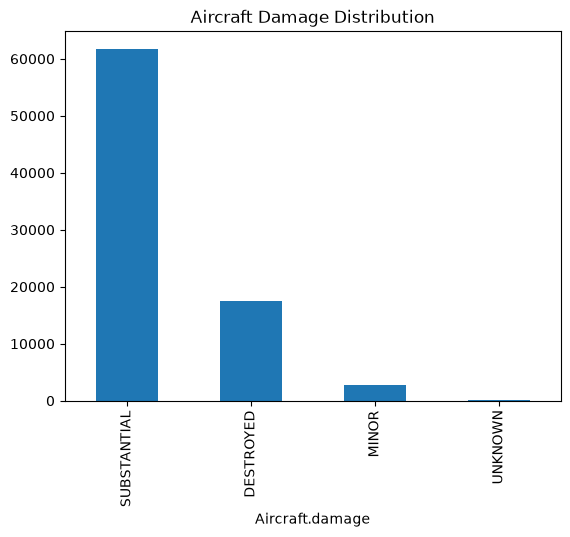

In [238]:
aviation_data_copy['Aircraft.damage'].value_counts().plot(kind='bar', title='Aircraft Damage Distribution', x='Aircraft Damage Type', y='Count of Aircraft')

In [239]:
aviation_data_copy['Aircraft.damage'].isna().sum()

np.int64(3138)

<Axes: title={'center': 'Aircraft Damage Distribution'}, xlabel='Aircraft.damage'>

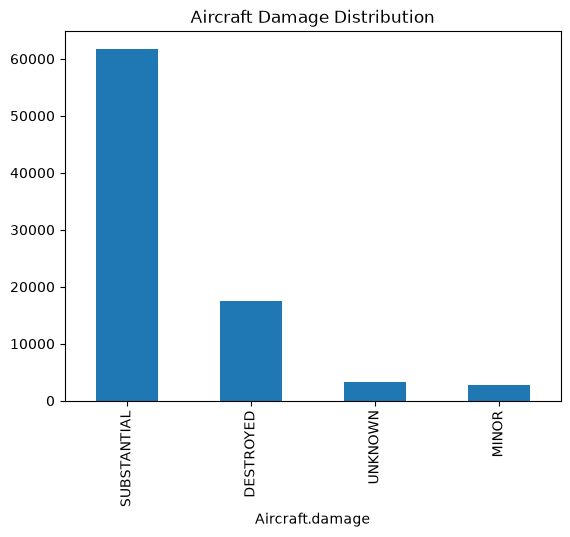

In [240]:
# As Aircraft damage count is at 2640, I decided to use Unknown as if I use the mode, the data will become misleading
aviation_data_copy['Aircraft.damage'] = aviation_data_copy['Aircraft.damage'].fillna('UNKNOWN')
aviation_data_copy['Aircraft.damage'].value_counts().plot(kind='bar', title='Aircraft Damage Distribution', x='Aircraft Damage Type', y='Count of Aircraft')

### Investigate the *Make* column
- Identify cleaning tasks here
- List cleaning tasks clearly in markdown
- Execute the cleaning tasks
- For your analysis, keep Makes with a reasonable number (you can put the threshold at 50 though lower could work as well)

In [241]:
#check for null values
aviation_data_copy['Make'].isna().sum()

np.int64(57)

In [242]:
#I used unkown as it can be a plane that has been made by enthusiasts in a workshop.
aviation_data_copy['Make'] = aviation_data_copy['Make'].fillna('UNKNOWN')
aviation_data_copy['Make'].value_counts()

Make
CESSNA               25814
PIPER                14142
BEECH                 5109
BOEING                2696
BELL                  2610
                     ...  
PHANTOM                  1
GREG HOBBS               1
JAMES R DERNOVSEK        1
ORLICAN S R O            1
ROYSE RALPH L            1
Name: count, Length: 7481, dtype: int64

### Inspect Model column
- Get rid of any NaNs.
- Inspect the column and counts for each model/make. Are model labels unique to each make?
- If not, create a derived column that is a unique identifier for a given plane type.

In [243]:
aviation_data_copy['Model'].isna().sum()

np.int64(78)

In [244]:
# Using unkown feels appropriate as model numbers cannot be shared among manufactures and their naming conventions differ per company
aviation_data_copy['Model'] = aviation_data_copy['Model'].fillna('UNKNOWN')
aviation_data_copy['Model'].value_counts()

Model
152             2232
172             1657
172N            1097
PA-28-140        869
172M             760
                ... 
DETRICK DA-2       1
XLT-RG             1
MH-60R             1
KITFOX S5          1
M-8 EAGLE          1
Name: count, Length: 11451, dtype: int64

### Cleaning other columns
- there are other columns containing data that might be related to the outcome of an accident. We list a few here:
- Engine.Type
- Weather.Condition
- Number.of.Engines
- Purpose.of.flight
- Broad.phase.of.flight

Inspect and identify potential cleaning tasks in each of the above columns. Execute those cleaning tasks. 

**Note**: You do not necessarily need to impute or drop NaNs here.

In [245]:
#I am checking for null values in engine type
aviation_data_copy['Engine.Type'].isna().sum()

np.int64(7095)

In [246]:
# I fill the null values for the engine type with unkown as it may be machined in a hobbist's shed
aviation_data_copy['Engine.Type'] = aviation_data_copy['Engine.Type'].fillna('UNKNOWN')
aviation_data_copy['Engine.Type'].value_counts()

Engine.Type
RECIPROCATING      66294
UNKNOWN             9064
TURBO SHAFT         3476
TURBO PROP          3305
TURBO FAN           2440
TURBO JET            682
GEARED TURBOFAN       12
ELECTRIC              10
LR                     2
NONE                   2
HYBRID ROCKET          1
UNK                    1
Name: count, dtype: int64

In [247]:
#Checking fo
aviation_data_copy['Number.of.Engines'].isna().sum()

np.int64(6083)

In [248]:
# I turned the number of engines as int as the number of engines cannot be a float
aviation_data_copy['Number.of.Engines'] = aviation_data_copy['Number.of.Engines'].fillna(aviation_data_copy['Number.of.Engines'].mean())
aviation_data_copy['Number.of.Engines'] = aviation_data_copy['Number.of.Engines'].astype(int)
aviation_data_copy['Number.of.Engines'].value_counts()

Number.of.Engines
1    72677
2    10580
0     1145
3      462
4      421
8        3
6        1
Name: count, dtype: int64

In [249]:
#Checking the weather condition column how many null values are there
aviation_data_copy['Weather.Condition'].isna().sum()

np.int64(4491)

In [250]:
# Checking for the mode
aviation_data_copy['Weather.Condition'].value_counts()

Weather.Condition
VMC    74094
IMC     5649
UNK     1055
Name: count, dtype: int64

In [251]:
# I assumed that as VMC is the mode of the weather condition, it makes it the most viable imputation
aviation_data_copy['Weather.Condition'] = aviation_data_copy['Weather.Condition'].fillna('VMC')
aviation_data_copy['Weather.Condition'].value_counts()

Weather.Condition
VMC    78585
IMC     5649
UNK     1055
Name: count, dtype: int64

In [252]:
aviation_data_copy['Broad.phase.of.flight'].isna().sum()

np.int64(27163)

In [253]:
# I have used UNKOWN as it has not been declared either by the owner of the aircraft to the radio tower or in registration of the aircraft
aviation_data_copy['Broad.phase.of.flight'] = aviation_data_copy['Broad.phase.of.flight'].fillna('UNKNOWN')
aviation_data_copy['Broad.phase.of.flight'].value_counts()

Broad.phase.of.flight
UNKNOWN        27657
LANDING        14486
TAKEOFF        11744
CRUISE          9653
MANEUVERING     7725
APPROACH        6157
CLIMB           1938
TAXI            1824
DESCENT         1792
GO-AROUND       1296
STANDING         910
OTHER            107
Name: count, dtype: int64

In [254]:
aviation_data_copy['Purpose.of.flight'].isna().sum()

np.int64(6187)

In [255]:
#I am using UNKOWN as it can be due to not being declared on the flight manifest or mightbe doing something illegal
aviation_data_copy['Purpose.of.flight'] = aviation_data_copy['Purpose.of.flight'].fillna('UNKNOWN')
aviation_data_copy['Purpose.of.flight'].value_counts()

Purpose.of.flight
PERSONAL                     47505
UNKNOWN                      12357
INSTRUCTIONAL                10185
AERIAL APPLICATION            4547
BUSINESS                      3722
POSITIONING                   1646
OTHER WORK USE                1264
AERIAL OBSERVATION             781
FERRY                          741
PUBLIC AIRCRAFT                715
EXECUTIVE/CORPORATE            501
FLIGHT TEST                    405
SKYDIVING                      180
EXTERNAL LOAD                  123
PUBLIC AIRCRAFT - FEDERAL      105
BANNER TOW                     101
AIR RACE SHOW                   99
PUBLIC AIRCRAFT - LOCAL         74
PUBLIC AIRCRAFT - STATE         64
AIR RACE/SHOW                   59
GLIDER TOW                      53
FIREFIGHTING                    40
AIR DROP                        11
ASHO                             6
PUBS                             4
PUBL                             1
Name: count, dtype: int64

### Column Removal
- inspect the dataframe and drop any columns that have too many NaNs

In [256]:
aviation_data_copy = aviation_data_copy.drop(columns=['Aircraft.Category','Latitude','Longitude','Airport.Code','Airport.Name','Schedule','Air.carrier','Location'])

### Save DataFrame to csv
- its generally useful to save data to file/server after its in a sufficiently cleaned or intermediate state
- the data can then be loaded directly in another notebook for further analysis
- this helps keep your notebooks and workflow readable, clean and modularized

In [257]:
aviation_data_copy.to_csv('C:/Users/user/OneDrive/Desktop/Data analysis Jet Airline Safety/dsc-course0-m8-lab/data/CleanedAviationData.csv', index=False)